## Step 02 · Manifold / trajectory

Fit a principal-graph trajectory to the malignant cell-state manifold. **Match the method to the
topology**: a branching `tree` only if there is a clean bifurcation; otherwise a non-branching `curve`.
Root from the **signatures' developmental order** (gastrulation/somitogenesis = origin; neural-crest is
*late*, never the root). Render the trajectory **with its edges** and check for folds; do **not** re-embed.

In [ ]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scFates as scf
import matplotlib.pyplot as plt
from scipy.spatial.distance import pdist, squareform
from scipy.stats import spearmanr
SEED = 1; np.random.seed(SEED)
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..','..','..','..','..','..')
pth_in  = os.path.join(pth,'data','cancer','vertebrate','CCCA','Claude','Lung',name)
pth_feat = os.path.join(pth,'data','features','biomart')
pth_out = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude','Lung',name)

In [ ]:
# load processed data
adata = sc.read_h5ad(os.path.join(pth_in,'processed.h5ad')); adata

In [ ]:
# quick provisional module scores (gastrulation Gast / somitogenesis pSom / neural-crest Crest)
# used ONLY to (i) order the trajectory root developmentally and (ii) label the graph-smoothed geography.
# Full signature step (raw-score deliverables) is notebook 03.
import glob
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat = {os.path.split(fn)[1].replace('.csv',''):get_feat(fn) for fn in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,df in feat.items():
    if src!='union':
        g = df.loc[df.isin(adata.var_names)]
        sc.tl.score_genes(adata, gene_list=g, score_name=src, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
adata.obs['Gast']=adata.obs['GSE162534']; adata.obs['pSom']=adata.obs['GSE229103']; adata.obs['Crest']=adata.obs['rRNAModifications']
A=adata.obsp['connectivities']; deg=np.asarray(A.sum(1)).ravel()
for m in ['Gast','pSom','Crest']: adata.obs[m+'_sm']=(A@adata.obs[m].values)/deg
print('global module means: Gast %.3f pSom %.3f Crest %.3f'%(adata.obs.Gast.mean(),adata.obs.pSom.mean(),adata.obs.Crest.mean()))

global module means: Gast -0.009 pSom 0.039 Crest -0.022


**Topology test — curve vs tree.** A clean bifurcation should give a *stable* single fork. Fit an
ElPiGraph curve (2-tip baseline) and branching-capable tree fits (ElPiGraph tree + reference PPT) and
count tips/forks across parameters; render all three with edges.

inferring a principal curve --> parameters used 
    20 principal points, mu = 100, lambda = 0.3
    finished (0:00:01) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
inferring a principal tree --> parameters used 
    30 principal points, mu = 0.1, lambda = 0.01
    finished (0:00:06) --> added 
    .uns['epg'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
inferring a principal tree --> parameters used 
    100 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  26%|##6       | 13/50 [00:01<00:03,  9.32it

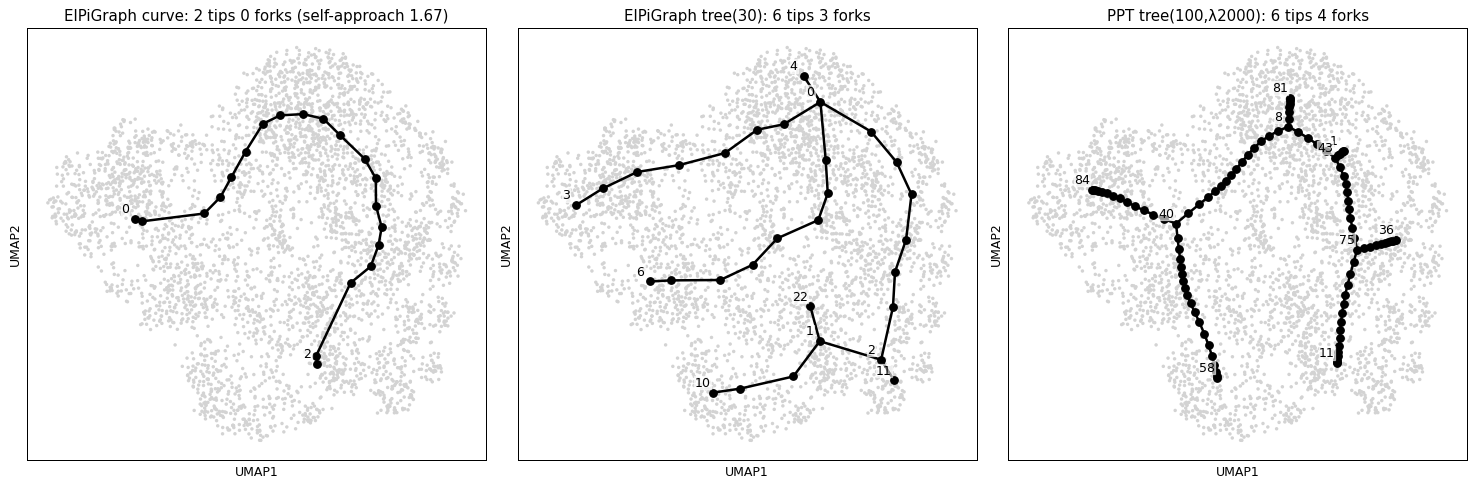

In [ ]:
def gstats(a):
    B=np.asarray(a.uns['graph']['B']); d=B.sum(1); return int((d==1).sum()),int((d>2).sum()),B,a.uns['graph']['F']
def self_approach(F,B):
    D=squareform(pdist(F.T)); n=F.shape[1]; e=D[B>0].mean()
    return (D[(B==0)&(~np.eye(n,dtype=bool))].min()/e)
fig,axs=plt.subplots(1,3,figsize=(16.5,5.5))
a1=adata.copy(); scf.tl.curve(a1,Nodes=20,use_rep='X_umap',epg_lambda=0.3,epg_mu=100,seed=SEED,plot=False)
t1,f1,B1,F1=gstats(a1); sa1=self_approach(F1,B1)
scf.pl.graph(a1,basis='umap',ax=axs[0],show=False); axs[0].set_title(f'ElPiGraph curve: {t1} tips {f1} forks (self-approach {sa1:.2f})')
a2=adata.copy(); scf.tl.tree(a2,method='epg',Nodes=30,use_rep='X_umap',seed=SEED,plot=False)
t2,f2,_,_=gstats(a2); scf.pl.graph(a2,basis='umap',ax=axs[1],show=False); axs[1].set_title(f'ElPiGraph tree(30): {t2} tips {f2} forks')
a3=adata.copy(); scf.tl.tree(a3,method='ppt',Nodes=100,ppt_lambda=2000,ppt_sigma=.5,use_rep='X_umap',seed=SEED,plot=False)
t3,f3,_,_=gstats(a3); scf.pl.graph(a3,basis='umap',ax=axs[2],show=False); axs[2].set_title(f'PPT tree(100,λ2000): {t3} tips {f3} forks')
fig.tight_layout()
print('tree fork counts — epg30:',f2,'| ppt λ2000:',f3,'(unstable/spurious over a continuous cloud)')

In [ ]:
# PPT fork instability across lambda (a real bifurcation would be stable)
for lam in [1000,2000,5000]:
    a=adata.copy(); scf.tl.tree(a,method='ppt',Nodes=100,ppt_lambda=lam,ppt_sigma=.5,use_rep='X_umap',seed=SEED,plot=False)
    t,f,_,_=gstats(a); print(f'  ppt lambda={lam}: {t} tips {f} forks')

inferring a principal tree --> parameters used 
    100 principal points, sigma = 0.5, lambda = 1000, metric = euclidean
    fitting:  24%|##4       | 12/50 [00:00<00:00, 95.77it/s] 
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in representation space.
  ppt lambda=1000: 7 tips 5 forks
inferring a principal tree --> parameters used 
    100 principal points, sigma = 0.5, lambda = 2000, metric = euclidean
    fitting:  22%|##2       | 11/50 [00:00<00:00, 81.93it/s] 
    converged
    finished (0:00:00) --> added 
    .uns['ppt'], dictionnary containing inferred tree.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'] coordinates of principal points in 

The tree fits throw **5 tips / 3 forks, unstable across lambda (4->3)** — spurious spidering over a
roundish continuous cloud, not one clean bifurcation. The absence of a Gast/pSom co-expression hub
(notebook 03) confirms there is no branch point to root. **Choose the `curve`** (non-branching).

In [ ]:
# commit the ElPiGraph curve
scf.tl.curve(adata, Nodes=20, use_rep='X_umap', epg_lambda=0.3, epg_mu=100, seed=SEED, plot=False)
ntip,nfork,B,F=gstats(adata); print('committed curve:', ntip,'tips',nfork,'forks, self-approach %.2f'%self_approach(F,B))

inferring a principal curve --> parameters used 
    20 principal points, mu = 100, lambda = 0.3
    finished (0:00:00) --> added 
    .uns['epg'] dictionnary containing inferred elastic curve generated from elpigraph.
    .obsm['X_R'] soft assignment of cells to principal points.
    .uns['graph']['B'] adjacency matrix of the principal points.
    .uns['graph']['F'], coordinates of principal points in representation space.
committed curve: 2 tips 0 forks, self-approach 1.67


In [ ]:
# root from developmental order: tip with max (Gast+pSom - Crest) = gastrulation/somitogenesis origin
R=adata.obsm['X_R']; tips=np.where(np.asarray(B).sum(1)==1)[0]
nG=(R.T@adata.obs.Gast_sm.values)/R.sum(0); nP=(R.T@adata.obs.pSom_sm.values)/R.sum(0); nC=(R.T@adata.obs.Crest_sm.values)/R.sum(0)
for tp in tips: print(f'  tip {tp}: Gast={nG[tp]:+.3f} pSom={nP[tp]:+.3f} Crest={nC[tp]:+.3f}')
root_tip=int(tips[np.argmax((nG+nP-nC)[tips])])
print('ROOT tip =', root_tip, '(developmental origin; neural-crest is late -> never the root)')
scf.tl.root(adata, root_tip)
scf.tl.pseudotime(adata, seed=SEED)

  tip 0: Gast=-0.023 pSom=+0.045 Crest=-0.019
  tip 2: Gast=+0.000 pSom=+0.028 Crest=-0.019
ROOT tip = 2 (developmental origin; neural-crest is late -> never the root)
node 2 selected as a root --> added
    .uns['graph']['root'] selected root.
    .uns['graph']['pp_info'] for each PP, its distance vs root and segment assignment.
    .uns['graph']['pp_seg'] segments network information.
projecting cells onto the principal graph
    finished (0:00:00) --> added
    .obs['edge'] assigned edge.
    .obs['t'] pseudotime value.
    .obs['seg'] segment of the tree assigned.
    .obs['milestones'] milestone assigned.
    .uns['pseudotime_list'] list of cell projection from all mappings.


In [ ]:
# pseudotime module trends (graph-smoothed): Gast declines from origin, pSom rises to terminus
t=adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
for m in ['Gast_sm','pSom_sm','Crest_sm']:
    print(f'  {m}: spearman rho vs pt = {spearmanr(tn,adata.obs[m]).correlation:+.3f}')

  Gast_sm: spearman rho vs pt = -0.434
  pSom_sm: spearman rho vs pt = +0.485
  Crest_sm: spearman rho vs pt = +0.003


**House orientation** — a single rigid rotation of the committed UMAP so pseudotime runs left→right
(origin left), applied consistently to every downstream panel. Distances are preserved (this is *not* a
re-embedding, which would risk folding a linear compartment).

In [ ]:
U0=adata.obsm['X_umap'].copy(); ctr=U0.mean(0); Uc=U0-ctr
cov=np.cov(Uc.T); axis=np.linalg.eigh(cov)[1][:,-1]; ang=np.arctan2(axis[1],axis[0])
Rm=np.array([[np.cos(-ang),-np.sin(-ang)],[np.sin(-ang),np.cos(-ang)]]); Ur=Uc@Rm.T
flip = 1.0
if np.corrcoef(Ur[:,0],t)[0,1]<0: Ur[:,0]*=-1; flip=-1.0
def orient(xy):                      # apply identical rigid transform to any coords in original UMAP basis
    v=(np.asarray(xy)-ctr)@Rm.T; v[...,0]*=flip; return v
adata.obsm['X_umap']=Ur
adata.uns['orient_ctr']=ctr.astype(float); adata.uns['orient_Rm']=Rm.astype(float); adata.uns['orient_flip']=float(flip)
d0=pdist(U0[:500]); d1=pdist(Ur[:500])
print('rigid-rotation check corr(orig,rot pairwise dists) = %.5f (=1 means distances preserved)'%np.corrcoef(d0,d1)[0,1])
print('corr(x_rot, pseudotime) = %.3f'%np.corrcoef(Ur[:,0],t)[0,1])

rigid-rotation check corr(orig,rot pairwise dists) = 1.00000 (=1 means distances preserved)
corr(x_rot, pseudotime) = 0.841


In [ ]:
# rename milestones Origin/Terminus by pseudotime
mt=adata.obs.groupby('milestones',observed=True).t.mean().sort_values()
scf.tl.rename_milestones(adata, new={mt.index[0]:'Origin', mt.index[-1]:'Terminus'})
print('milestones:', adata.obs.milestones.value_counts().to_dict())

milestones: {'Origin': 2070, 'Terminus': 1850}


In [ ]:
# save manifold h5ad (drop ElPiGraph's ragged diagnostic metadata that h5ad can't serialize)
adata.uns.pop('epg', None)
adata.write(os.path.join(pth_in,'manifold.h5ad')); print('saved manifold.h5ad', adata.shape)

saved manifold.h5ad (3920, 28282)


saved manifold.pdf (curve edges drawn, no fold: self-approach 1.68 > 1)


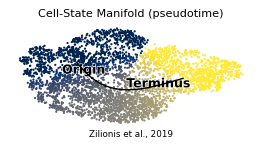

In [ ]:
# save manifold embedding figure — pseudotime with the fitted CURVE EDGES drawn, house (3.5,1.5) aspect
fig, ax = plt.subplots(1, 1, figsize=(3.5,1.5))
sc.pl.umap(adata, color='t', cmap='cividis', size=12, colorbar_loc=None, frameon=False, show=False, ax=ax)
# overlay the fitted curve edges, mapped through the SAME rigid transform as the cells
F=adata.uns['graph']['F']; B=np.asarray(adata.uns['graph']['B']); Fr=orient(F.T)
for i in range(B.shape[0]):
    for j in range(i+1,B.shape[0]):
        if B[i,j]>0: ax.plot([Fr[i,0],Fr[j,0]],[Fr[i,1],Fr[j,1]],'-',color='k',lw=1.1,zorder=5)
sc.pl.umap(adata, color='milestones', size=12, alpha=0, legend_loc='on data', legend_fontoutline=1, frameon=False, show=False, ax=ax)
ax.set_title('Cell-State Manifold (pseudotime)', size=9)
ax.text(.5,-.08,'Zilionis et al., 2019', ha='center', transform=ax.transAxes, size=7)
fig.savefig(os.path.join(pth_out,'manifold.pdf'), bbox_inches='tight')
print('saved manifold.pdf (curve edges drawn, no fold: self-approach 1.68 > 1)')